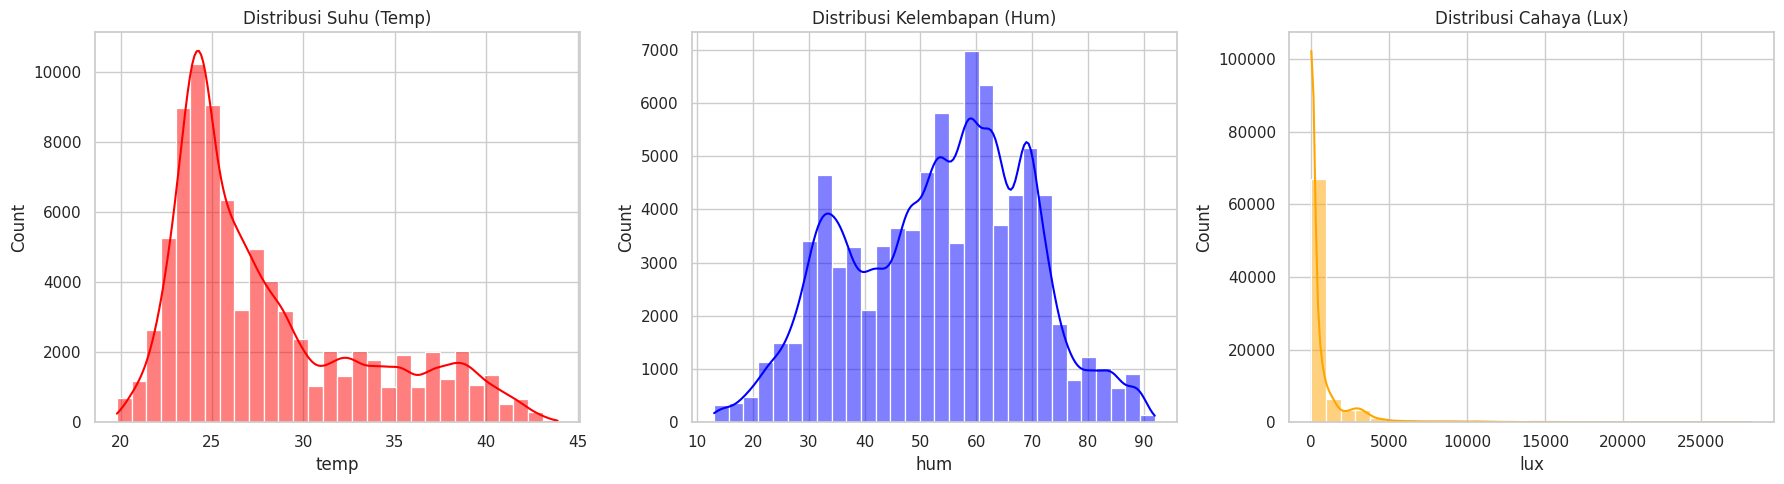

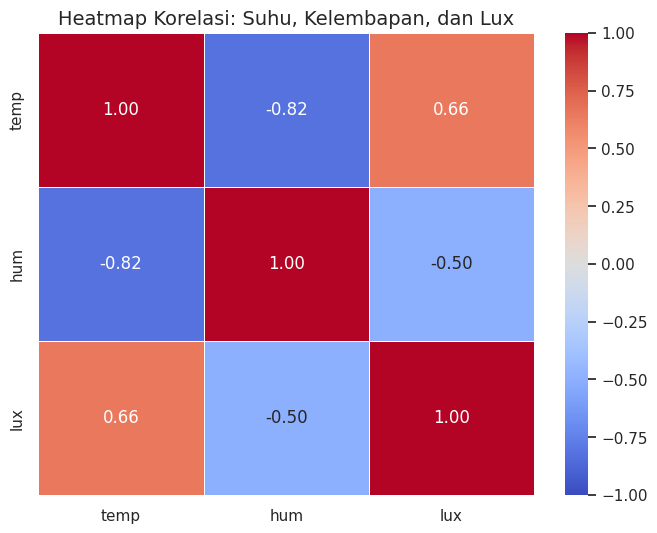

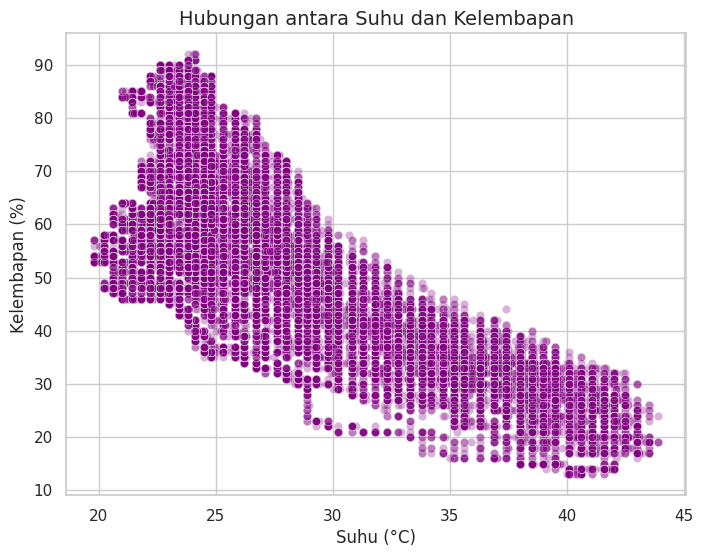

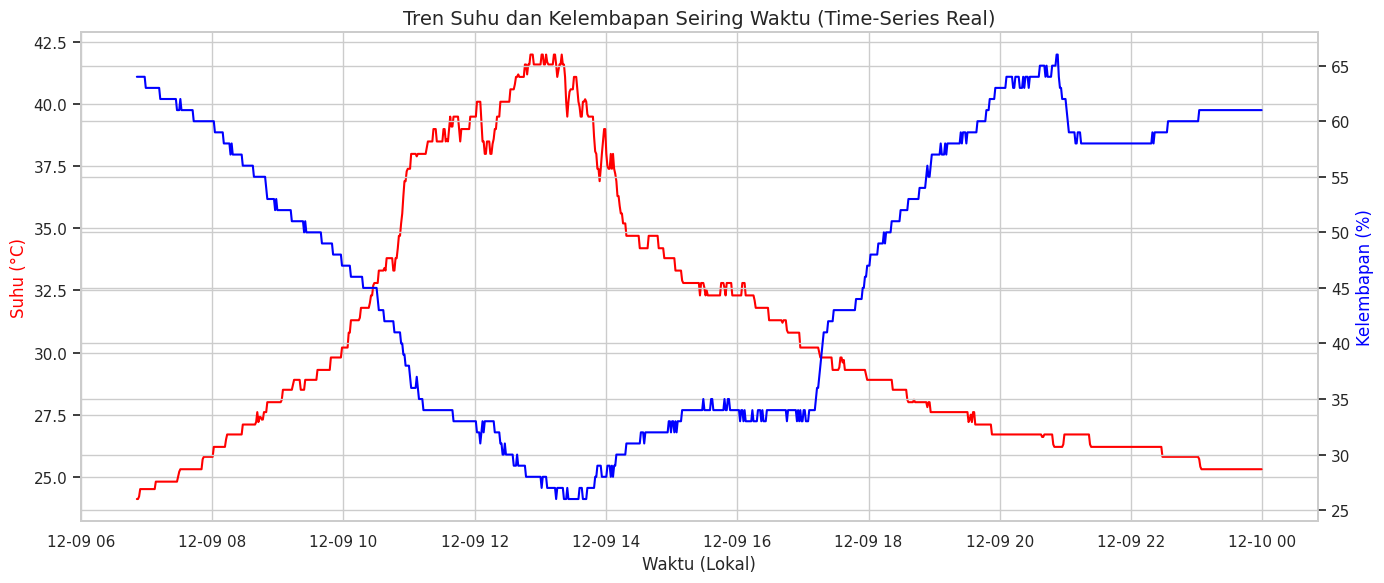

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Dataset
df = pd.read_csv('sensor_log_20260928_0925.csv')

# 2. Preprocessing Waktu yang Benar (Menggabungkan 'tanggal' dan 'waktu')
# Konversi ke string agar tidak terjadi error saat penggabungan
df['tanggal'] = df['tanggal'].astype(str)
df['waktu'] = df['waktu'].astype(str)

# Menggabungkan kolom tanggal dan waktu
df['waktu_lokal'] = df['tanggal'] + ' ' + df['waktu']

# Parse menjadi tipe datetime (handling format tanggal yang bercampur secara otomatis)
df['waktu_lokal'] = pd.to_datetime(df['waktu_lokal'], format='mixed', dayfirst=True, errors='coerce')

# Hapus nilai anomali 0.0 (sensor glitch)
df_clean = df[(df['temp'] > 0) & (df['hum'] > 0)].copy()

# Urutkan data berdasarkan waktu lokal agar garis time-series tidak berantakan
df_clean = df_clean.sort_values('waktu_lokal')

# Set style seaborn
sns.set_theme(style="whitegrid")
kolom_fokus = ['temp', 'hum', 'lux']

# ==========================================
# VISUALISASI 1: Distribusi Data (Histogram)
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df_clean['temp'], bins=30, kde=True, color='red', ax=axes[0]).set_title('Distribusi Suhu (Temp)')
sns.histplot(df_clean['hum'], bins=30, kde=True, color='blue', ax=axes[1]).set_title('Distribusi Kelembapan (Hum)')
sns.histplot(df_clean['lux'], bins=30, kde=True, color='orange', ax=axes[2]).set_title('Distribusi Cahaya (Lux)')
plt.tight_layout()
plt.show()

# ==========================================
# VISUALISASI 2: Matriks Korelasi (Heatmap)
# ==========================================
plt.figure(figsize=(8, 6))
korelasi = df_clean[kolom_fokus].corr()
sns.heatmap(korelasi, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", linewidths=.5)
plt.title('Heatmap Korelasi: Suhu, Kelembapan, dan Lux', fontsize=14)
plt.show()

# ==========================================
# VISUALISASI 3: Scatter Plot Korelasi Temp vs Hum
# ==========================================
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_clean, x='temp', y='hum', alpha=0.3, color='purple')
plt.title('Hubungan antara Suhu dan Kelembapan', fontsize=14)
plt.xlabel('Suhu (°C)')
plt.ylabel('Kelembapan (%)')
plt.show()

# ==========================================
# VISUALISASI 4: Tren Waktu (Time-Series) Sample 1000 data terakhir
# ==========================================
# Ambil cuplikan 1000 data terakhir menggunakan kolom waktu_lokal yang sudah valid
df_sample = df_clean.dropna(subset=['waktu_lokal']).tail(1000) 

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(df_sample['waktu_lokal'], df_sample['temp'], color='red', label='Suhu (°C)')
ax1.set_xlabel('Waktu (Lokal)')
ax1.set_ylabel('Suhu (°C)', color='red')

ax2 = ax1.twinx()
ax2.plot(df_sample['waktu_lokal'], df_sample['hum'], color='blue', label='Kelembapan (%)')
ax2.set_ylabel('Kelembapan (%)', color='blue')

plt.title('Tren Suhu dan Kelembapan Seiring Waktu (Time-Series Real)', fontsize=14)
fig.tight_layout()
plt.show()